# 02. Сравнение моделей цены аренды

**Критерий выбора – минимальная MAE на validation.** Для подсказки арендодателю важно, на сколько рублей в среднем прогноз месячной аренды отличается от указанной в объявлении цены. MAE учитывает завышение и занижение цены одинаково. Дополнительно считаем RMSE в рублях, чтобы видеть влияние крупных промахов, и R², чтобы оценить долю объяснённой дисперсии цены.

## Подготовленные выборки

Берём train и validation из первого ноутбука. Параметры предобработки уже рассчитаны на train. Отделяем цену `rent_rub` от признаков и используем одни и те же строки validation для всех моделей.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from modules import RANDOM_STATE

processed_dir = PROJECT_ROOT / "data" / "processed"
train = pd.read_csv(processed_dir / "train.csv")
validation = pd.read_csv(processed_dir / "validation.csv")

TARGET = "rent_rub"
X_train, y_train = train.drop(columns=TARGET), train[TARGET]
X_validation, y_validation = validation.drop(columns=TARGET), validation[TARGET]
assert X_train.columns.equals(X_validation.columns)

print("Объявлений в train –", len(X_train))
print("Объявлений в validation –", len(X_validation))
print("Признаков –", X_train.shape[1])

Объявлений в train – 7776
Объявлений в validation – 1944
Признаков – 54


## Модели

Для первого сравнения фиксируем по одной конфигурации каждой модели.

- **DummyRegressor** предсказывает медиану аренды на train для любого объявления. Медиана даёт минимальную абсолютную ошибку среди постоянных прогнозов на train.
- **Ridge** оценивает линейную зависимость цены от признаков. Берём стандартную силу регуляризации `alpha=1`.
- **Дерево решений** может учитывать сочетания признаков. Ограничиваем глубину восемью уровнями и задаём минимум пять объявлений в листе, чтобы избежать прогнозов по единичным примерам.
- **kNN** усредняет цены десяти ближайших объявлений. Расстояния считаются по подготовленным признакам, в которых числовые столбцы уже стандартизированы.

In [2]:
models = {
    "DummyRegressor": DummyRegressor(strategy="median"),
    "Ridge": Ridge(alpha=1.0),
    "Дерево решений": DecisionTreeRegressor(
        max_depth=8, min_samples_leaf=5, random_state=RANDOM_STATE
    ),
    "kNN": KNeighborsRegressor(n_neighbors=10),
}

def validation_metrics(predicted):
    return {
        "MAE, ₽": mean_absolute_error(y_validation, predicted),
        "RMSE, ₽": root_mean_squared_error(y_validation, predicted),
        "R²": r2_score(y_validation, predicted),
        "Отрицательных прогнозов": (predicted < 0).sum(),
    }

for model in models.values():
    model.fit(X_train, y_train)

predictions = {name: model.predict(X_validation) for name, model in models.items()}
results = pd.DataFrame.from_dict(
    {name: validation_metrics(predicted) for name, predicted in predictions.items()},
    orient="index",
).rename_axis("Модель").sort_values("MAE, ₽")

results.round({"MAE, ₽": 2, "RMSE, ₽": 2, "R²": 3})

,"MAE, ₽","RMSE, ₽",R²,Отрицательных прогнозов
Модель,,,,
Ridge,4751.06,7209.58,0.784,7
Дерево решений,4807.55,7403.07,0.772,0
kNN,4873.35,7808.49,0.747,0
DummyRegressor,10089.25,16137.86,-0.081,0


## Проверка логарифма цены

В первом сравнении у Ridge самая низкая MAE – 4 751 ₽. У неё семь отрицательных прогнозов, а цены аренды положительны. Простая линейная модель прибавляет к цене фиксированную сумму за изменение признака. Обучение на логарифме позволяет выразить тот же эффект как множитель цены. Проверим этот вариант с тем же `alpha=1` и теми же признаками. После обратного преобразования считаем ошибки в рублях.

In [3]:
assert (y_train > 0).all()

log_ridge = TransformedTargetRegressor(
    regressor=Ridge(alpha=1.0), func=np.log, inverse_func=np.exp
)
log_ridge.fit(X_train, y_train)
log_name = "Ridge на log(цене)"
models[log_name] = log_ridge
predictions[log_name] = log_ridge.predict(X_validation)
results.loc[log_name] = validation_metrics(predictions[log_name])
results["Отрицательных прогнозов"] = results["Отрицательных прогнозов"].astype(int)
results = results.sort_values("MAE, ₽")

results.round({"MAE, ₽": 2, "RMSE, ₽": 2, "R²": 3})

,"MAE, ₽","RMSE, ₽",R²,Отрицательных прогнозов
Модель,,,,
Ridge на log(цене),3606.46,5782.17,0.861,0
Ridge,4751.06,7209.58,0.784,7
Дерево решений,4807.55,7403.07,0.772,0
kNN,4873.35,7808.49,0.747,0
DummyRegressor,10089.25,16137.86,-0.081,0


После проверки гипотезы минимальная MAE у Ridge на логарифме цены – 3 606 ₽ против 4 751 ₽ у обычной Ridge. Снижение относительно обычной Ridge составляет около 24 %. Все 1 944 прогноза новой модели положительны. Эту же validation использовали, чтобы заметить проблему и сравнить варианты. Независимую оценку даст отложенный тест.

## Остатки на validation

Берём модель с минимальной MAE в таблице. Остаток считаем как цену из объявления минус прогноз. Положительный остаток означает, что модель занизила цену, отрицательный – завысила. Для разбора сохраняем номер объявления и исходные характеристики. Проверяем соответствие сырых и подготовленных строк по цене и всем признакам.

In [4]:
import joblib
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline

from modules.preprocessing import prepare_features

best_name = results["MAE, ₽"].idxmin()
best_model = models[best_name]
prediction = predictions[best_name]

raw_validation = pd.read_csv(
    PROJECT_ROOT / "data" / "interim" / "validation_raw.csv", dtype=str, keep_default_na=False
)
raw_features = raw_validation.drop(columns=TARGET)
preprocessor = joblib.load(PROJECT_ROOT / "models" / "preprocessor.joblib")
pd.testing.assert_series_equal(pd.to_numeric(raw_validation[TARGET]), y_validation)
pd.testing.assert_frame_equal(preprocessor.transform(raw_features), X_validation, check_exact=False)

errors = raw_validation[["listing_id", "rooms", "total_area", "renovation"]].copy()
errors["district"] = prepare_features(raw_features)["district"].fillna("не указано")
errors["actual"] = y_validation
errors["prediction"] = prediction
errors["residual"] = errors["actual"] - errors["prediction"]
errors["absolute_error"] = errors["residual"].abs()

print("Средний остаток, ₽ –", round(errors["residual"].mean()))
print("Медианный остаток, ₽ –", round(errors["residual"].median()))
print("Отрицательных прогнозов –", (errors["prediction"] < 0).sum())
print("Диапазон остатков, ₽ –", round(errors["residual"].min()), "…", round(errors["residual"].max()))

Средний остаток, ₽ – 462
Медианный остаток, ₽ – 0
Отрицательных прогнозов – 0
Диапазон остатков, ₽ – -35953 … 68710


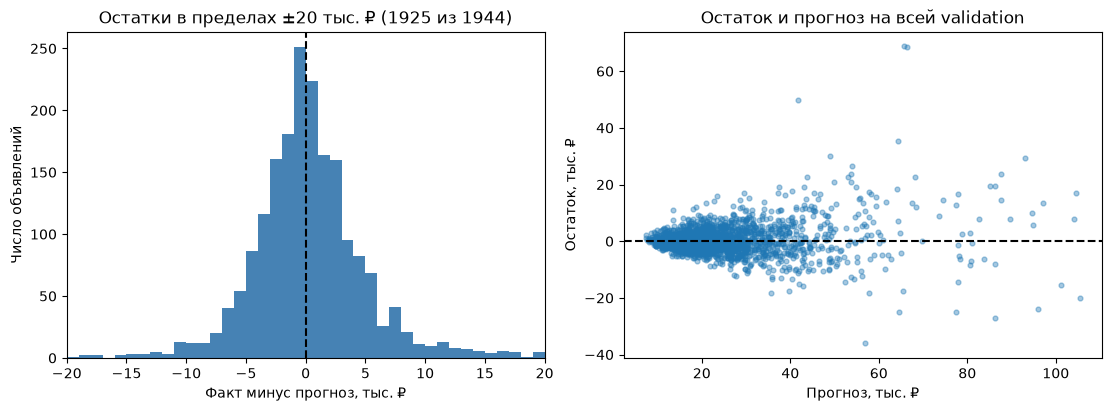

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
residual_k = errors["residual"] / 1000
central = residual_k.between(-20, 20)
axes[0].hist(residual_k[central], bins=range(-20, 21), color="steelblue")
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set(xlim=(-20, 20), title=f"Остатки в пределах ±20 тыс. ₽ ({central.sum()} из {len(central)})",
            xlabel="Факт минус прогноз, тыс. ₽", ylabel="Число объявлений")

axes[1].scatter(errors["prediction"] / 1000, errors["residual"] / 1000, s=12, alpha=0.4)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(title="Остаток и прогноз на всей validation", xlabel="Прогноз, тыс. ₽", ylabel="Остаток, тыс. ₽")
plt.show()

На гистограмме пик около нуля. За пределами ±20 000 ₽ оказались 19 из 1 944 объявлений. В 14 случаях цена занижена, в пяти – завышена. Крайние остатки видны на диаграмме справа. Наибольшее занижение – 68 710 ₽, наибольшее завышение – 35 953 ₽. Средний остаток положительный (462 ₽), а медианный при округлении до рубля равен нулю.

### Ошибки по цене и району

Группируем объявления по фактической месячной цене. Для каждой группы считаем число объявлений, MAE и средний остаток в рублях. Размер группы помогает понять, сколько наблюдений стоит за средним.

In [6]:
errors["price_group"] = pd.cut(
    errors["actual"], bins=[-np.inf, 20000, 40000, 60000, np.inf], right=False,
    labels=["до 20 тыс.", "от 20 до 40 тыс.", "от 40 до 60 тыс.", "от 60 тыс."],
)

def segment_errors(column):
    return errors.groupby(column, observed=True).agg(
        Объявлений=("residual", "size"),
        MAE=("absolute_error", "mean"),
        Средний_остаток=("residual", "mean"),
    ).round()

price_summary = segment_errors("price_group")
ridge_error = (y_validation - predictions["Ridge"]).abs()
price_summary["MAE обычной Ridge"] = ridge_error.groupby(errors["price_group"], observed=True).mean().round()
price_summary

,Объявлений,MAE,Средний_остаток,MAE обычной Ridge
price_group,,,,
до 20 тыс.,792,1984.0,-956.0,3441.0
от 20 до 40 тыс.,899,3556.0,279.0,4534.0
от 40 до 60 тыс.,177,6328.0,2960.0,5066.0
от 60 тыс.,76,14774.0,11577.0,20231.0


In [7]:
segment_errors("district").sort_values("MAE", ascending=False)

,Объявлений,MAE,Средний_остаток
district,,,
центральный,133,8351.0,2661.0
не указано,8,6520.0,938.0
октябрьский,161,6343.0,1419.0
советский,196,3726.0,711.0
ленинский,206,3383.0,-206.0
заречный,155,3380.0,372.0
первомайский,182,3214.0,426.0
кировский,191,3144.0,351.0
зареченский,7,2978.0,-1347.0


В группе от 60 000 ₽ (76 из 1 944 объявлений) MAE снизилась с 20 231 до 14 774 ₽. Среднее занижение здесь составляет 11 577 ₽. В группе от 40 000 до 60 000 ₽ результат ухудшился – MAE выросла с 5 066 до 6 328 ₽.

Среди известных районов наибольшая MAE у Центрального – 8 351 ₽ по 133 объявлениям. В Промышленном она составляет 1 916 ₽ по 144 объявлениям. У восьми объявлений район пропущен, поэтому оценка для этой группы особенно чувствительна к единичным промахам.

### Объявления с наибольшей абсолютной ошибкой

In [8]:
errors.nlargest(5, "absolute_error")[[
    "listing_id", "district", "rooms", "total_area", "renovation",
    "actual", "prediction", "residual", "absolute_error",
]].round()

,listing_id,district,rooms,total_area,renovation,actual,prediction,residual,absolute_error
248,621ef826,центральный,4,114.8,косметический,134500,65790.0,68710.0,68710.0
1522,ed605cca,центральный,2,93.3,евроремонт,135000,66336.0,68664.0,68664.0
576,c0a0c792,центральный,3,85.4,,91500,41748.0,49752.0,49752.0
500,40957bc3,центральный,студия,233.0,евроремонт,21000,56953.0,-35953.0,35953.0
443,4f2dcaf4,центральный,3,98.9,косметический,99500,64286.0,35214.0,35214.0


Все пять крупнейших промахов пришлись на Центральный район. Самый большой – у четырёхкомнатной квартиры площадью 114,8 м². В объявлении указано 134 500 ₽, прогноз – 65 790 ₽. Есть и обратный пример. Для студии с указанной площадью 233 м² прогноз составил 56 953 ₽ при цене 21 000 ₽. Необычная площадь могла повлиять на прогноз, поэтому для таких объявлений имеет смысл проверять исходные характеристики.

### Коэффициенты Ridge на логарифме цены

При росте стандартизированного числового признака на одно стандартное отклонение train вклад коэффициента в логарифм цены равен β. После обратного преобразования цена умножается на exp(β). Поэтому изменение в процентах от исходного прогноза равно 100 × (exp(β) − 1) при остальных фиксированных признаках. Для сравнения двух категорий одного поля берём разность их коэффициентов.

In [9]:
coefficients = pd.Series(best_model.regressor_.coef_, index=X_train.columns)
effects = coefficients.loc[["living_area", "distance_to_center_km", "building_age", "log_total_area"]].copy()
effects.loc["дизайнерский ремонт вместо отсутствия ремонта"] = (
    coefficients["renovation_дизайнерский"] - coefficients["renovation_без ремонта"]
)
(100 * np.expm1(effects)).round(1).rename("Изменение относительно исходного прогноза, %")

living_area                                       9.5
distance_to_center_km                            -5.9
building_age                                     -4.2
log_total_area                                   10.5
дизайнерский ремонт вместо отсутствия ремонта    46.2
Name: Изменение относительно исходного прогноза, %, dtype: float64

При росте жилой площади на одно стандартное отклонение прогноз выше на 9,5 % относительно исходной оценки при прочих равных. Такой же шаг для расстояния до центра связан со снижением прогноза на 5,9 %. Замена категории «без ремонта» на «дизайнерский» при тех же характеристиках квартиры повышает прогноз на 46,2 % относительно оценки квартиры без ремонта.

**Вывод для подсказки цены.** Модель даёт положительный ориентир в рублях. При фактической цене от 20 000 до 40 000 ₽ средний абсолютный промах составляет 3 556 ₽. Для дорогих квартир ошибки крупнее. Четыре из пяти самых больших промахов – занижения цены в Центральном районе. Следующая гипотеза для проверки – зависит ли надбавка за дополнительную площадь от района.

### Сохранение модели

Соединяем обученную предобработку и выбранную модель в одном пайплайне. После загрузки подаём ему сырые признаки всей validation и сравниваем прогнозы с теми, по которым считали метрики.

In [10]:
rent_model = Pipeline([("preprocessing", preprocessor), ("model", best_model)])
model_path = PROJECT_ROOT / "models" / "rent_model.joblib"
joblib.dump(rent_model, model_path)

loaded_model = joblib.load(model_path)
np.testing.assert_allclose(loaded_model.predict(raw_features), prediction, rtol=0, atol=1e-7)
print(f"Сохранена модель {best_name}. Совпали прогнозы для {len(raw_features)} объявлений.")

Сохранена модель Ridge на log(цене). Совпали прогнозы для 1944 объявлений.
